Generate detailed distribution insights through violin plots and swarm plots, incorporating statistical summaries and density estimations to facilitate comparison across multiple data segments.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 120
segments = np.random.choice(['Enterprise', 'Mid-Market', 'SMB'], size=n_samples, p=[0.3, 0.4, 0.3])

In [4]:
spend = []
for s in segments:
    if s == 'Enterprise':
        spend.append(np.random.gamma(shape=5, scale=2000))
    elif s == 'Mid-Market':
        spend.append(np.random.normal(loc=4500, scale=1200))
    else:  # SMB
        spend.append(np.random.exponential(scale=2000) + 500)

df_dist = pd.DataFrame({
    'segment': segments,
    'annual_spend': np.round(spend, 2)
})

In [5]:
print(df_dist.head())

      segment  annual_spend
0  Mid-Market       3657.54
1         SMB       1017.37
2         SMB       1614.12
3  Mid-Market       4106.81
4  Enterprise      10672.07


In [6]:
summary_stats = df_dist.groupby('segment')['annual_spend'].agg(
    count='count',
    mean='mean',
    std='std',
    median='median',
    q25=lambda x: np.percentile(x, 25),
    q75=lambda x: np.percentile(x, 75)
)

In [8]:
summary_stats['IQR'] = summary_stats['q75'] - summary_stats['q25']

print("Statistical Distribution Summaries")
print(summary_stats.round(2))

Statistical Distribution Summaries
            count      mean      std   median      q25       q75      IQR
segment                                                                  
Enterprise     41  10036.48  3562.98  9782.55  7389.45  12623.37  5233.92
Mid-Market     42   4697.93  1252.72  4586.30  3968.35   5375.25  1406.90
SMB            37   2499.65  1753.89  2188.22  1159.15   3063.52  1904.37


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

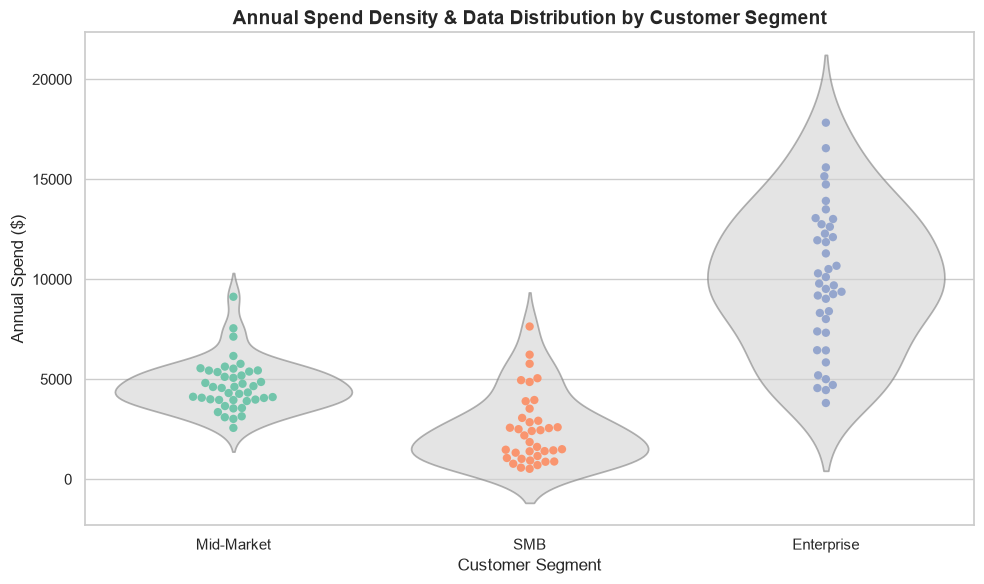

In [16]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_dist,
    x='segment',
    y='annual_spend',
    inner=None,          
    color='lightgray',
    density_norm='width',
    alpha=0.6
)

sns.swarmplot(
    data=df_dist,
    x='segment',
    y='annual_spend',
    hue='segment',
    palette='Set2',
    size=6,
    alpha=0.9
)

plt.title('Annual Spend Density & Data Distribution by Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Annual Spend ($)', fontsize=12)
plt.legend([], frameon=False)  
plt.tight_layout()

plt.show()

In [17]:
df_dist['renewed'] = np.random.choice(['Yes', 'No'], size=n_samples, p=[0.7, 0.3])

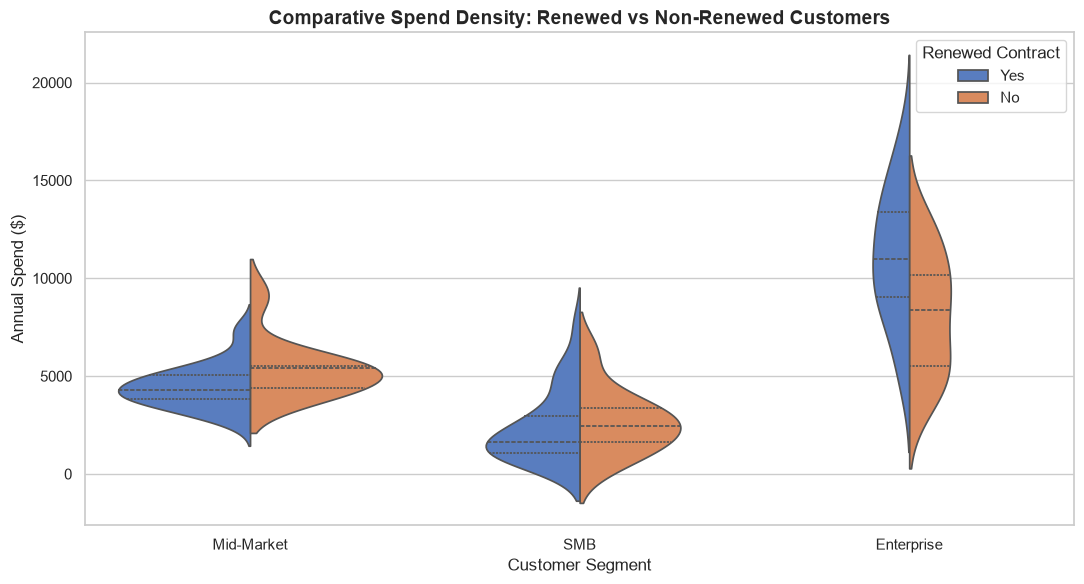

In [20]:
plt.figure(figsize=(11, 6))
sns.violinplot(
    data=df_dist,
    x='segment',
    y='annual_spend',
    hue='renewed',
    split=True,          
    inner='quartile',   
    palette='muted'
)
plt.title('Comparative Spend Density: Renewed vs Non-Renewed Customers', fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Annual Spend ($)', fontsize=12)
plt.legend(title='Renewed Contract', loc='upper right')
plt.tight_layout()

plt.show()